**Vision-Based Gaze Estimation | Presented by: Reza Saadatyar (2026)**

**02 | Eye Images, Geometry and Data Quality**

![Study-specific MPIIGaze research workflow and evidence boundaries](../../images/02_eye_images_geometry_and_quality.svg)

**Objective:** Decode source-aligned normalised MPIIGaze eye photographs and corresponding gaze vectors; construct a bounded participant-level sample with independent outer/inner evaluation roles.

**Scope:** Original source MATLAB images are locally processed. Source images are not uploaded to Git. No models are fitted in this notebook.

**Scientific protocol:** The preliminary cohort uses deterministic selection of up to 500 left-eye images per observed person; it is not the publisher's official Evaluation Subset.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess
repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/",1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git","clone","-q",repo_url,str(repo_path)],check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("vision_based_gaze_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 5. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from mpiigaze_data import build_eye_sample_cache
from mpiigaze_io import (ensure_mpiigaze_source, normalised_mat_files,
                         is_normalised_mat_path)
from gaze_evaluation import participant_fold_table
from gaze_geometry import angular_error_degrees

# ------------------- 6. Output Directory and Setup Summary -------------------
out_dir = root / "vision_based_gaze_estimation" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
raw_dir = root / "data" / "raw" / "mpiigaze"
processed_dir = root / "data" / "processed" / "mpiigaze"
processed_dir.mkdir(parents=True, exist_ok=True)
cache_path = processed_dir / "02_normalised_eye_cache.npz"
plot_style(font_family="DejaVu Sans", title_size=12.5,
           title_weight="normal", label_size=11.5,
           label_weight="normal", tick_size=11, legend_size=10,
           figure_dpi=100, figure_size=(9,4))
print("Study outputs:",out_dir)
print("Git-ignored image cache:",cache_path)
print("Python:",sys.version.split()[0])

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/vision_based_gaze_estimation/output
Git-ignored image cache: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/mpiigaze/02_normalised_eye_cache.npz
Python: 3.13.18


**02. Validate Notebook-01 Source Inputs**

Read the source inventory and select participant/day normalised MAT paths. Reconcile selected paths and file sizes with the runtime source before decoding images.

In [ ]:
# ================== 02. Verify Source and Dataset Contract ===================


inventory_path = out_dir / "01_file_inventory.csv"
if not inventory_path.is_file():
    raise FileNotFoundError(f"Run Notebook 01 to create {inventory_path}")
inventory = pd.read_csv(inventory_path)
if inventory.empty or inventory.relative_path.duplicated().any():
    raise ValueError("Source inventory is empty or contains duplicate paths")
# -------------------- 2. Reuse or Recover Runtime Source ---------------------
raw_dir = ensure_mpiigaze_source(raw_dir)
expected = inventory.loc[
    inventory.relative_path.map(is_normalised_mat_path),
    ["relative_path", "size_bytes"]]
expected = {
    row.relative_path: int(row.size_bytes)
    for row in expected.itertuples(index=False)
}
observed = {
    path.relative_to(raw_dir).as_posix(): path.stat().st_size
    for path in normalised_mat_files(raw_dir)
}
if not expected or expected != observed:
    raise ValueError(
        "The current normalised source differs from the Notebook-01 "
        "inventory. Rerun Notebook 01 against this release before continuing.")
print("Observed original source files:",len(inventory))
print("Participant/day MAT paths:", len(observed))

Reusing MPIIGaze runtime cache: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/mpiigaze
Normalised MAT containers: 521
Observed original source files: 430180
Participant/day MAT paths: 521


**03. Decode a Source-Matched Image Sample**

The decoder matches original normalised MATLAB image rows to gaze angles or vectors. The sampling cap is applied independently within each participant and does not inspect gaze outcomes.

In [ ]:
# ================== 03. Extract Matched Gaze and Eye Images ==================

# ------------------------ 1. Define the Source Subset ------------------------
SOURCE_EYE = "left"
MAX_IMAGES_PER_PERSON = 500
SEED = 17

# ----------------------- 2. Read Original MATLAB Rows ------------------------
records,images,gaze,source_counts = build_eye_sample_cache(
    raw_dir,eye=SOURCE_EYE,per_person=MAX_IMAGES_PER_PERSON,seed=SEED)
samples = pd.DataFrame(records)
if samples.sample_id.duplicated().any() or samples.empty:
    raise ValueError("Image sample identities are missing or duplicated")
if not np.allclose(np.linalg.norm(gaze,axis=1),1.,atol=1e-5):
    raise ValueError("The original 3D gaze vectors are not unit length")
print("Source image rows inspected:",sum(source_counts.values()))
print("Selected source-matched samples:",len(samples))
print("Image dimensions:",images.shape)
display(samples.groupby("participant_id").size().rename("images"))

Source image rows inspected: 213658
Selected source-matched samples: 7500
Image dimensions: (7500, 36, 60)


,images
participant_id,
p00,500
p01,500
p02,500
p03,500
p04,500
p05,500
p06,500
p07,500
p08,500


**04. Define Nested Participant-Disjoint Folds**

One outer participant is reserved per fold. Inner validation people are selected without the outer Test person; image-level random splitting is prohibited.

In [5]:
# ================= 04. Define Independent-Person Evaluation ==================

folds = participant_fold_table(
    samples.participant_id.unique(),seed=SEED,inner_people=2)
outer = folds.loc[folds.role.eq("test")]
if outer.participant_id.duplicated().any() or set(outer.participant_id)!=set(samples.participant_id):
    raise ValueError("Outer fold assignments are not participant-disjoint")
print("Outer LOPO folds:",folds.fold_id.nunique())
display(folds.groupby(["fold_id","role"]).size().unstack(fill_value=0))

Outer LOPO folds: 15


role,test,train,validation
fold_id,,,
outer_01,1,12,2
outer_02,1,12,2
outer_03,1,12,2
outer_04,1,12,2
outer_05,1,12,2
outer_06,1,12,2
outer_07,1,12,2
outer_08,1,12,2
outer_09,1,12,2


**05. Inspect Pixel Quality and Geometry**

Visual diagnostics use the actual image pixels and record mean intensity and contrast. Example eye patches are displayed locally, not exported or embedded in the published workflow diagram.

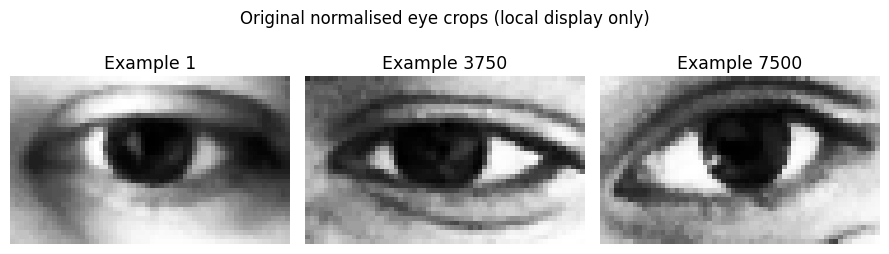

In [6]:
# ==================== 05. Inspect Original Image Quality =====================

flat = images.reshape(len(images),-1).astype(np.float32)
samples["mean_pixel_intensity"] = flat.mean(axis=1)
samples["pixel_std"] = flat.std(axis=1)
if not np.isfinite(samples[["mean_pixel_intensity","pixel_std"]]).all().all():
    raise ValueError("Non-finite image statistics")
fig,axes=plt.subplots(1,3,figsize=(9,2.8))
for ax,idx in zip(axes,np.linspace(0,len(images)-1,3,dtype=int)):
    ax.imshow(images[idx],cmap="gray",vmin=0,vmax=255)
    ax.set(title=f"Example {idx+1}")
    ax.axis("off")
fig.suptitle("Original normalised eye crops (local display only)")
fig.tight_layout()
plt.show()
if not np.allclose(angular_error_degrees(gaze[:1],gaze[:1]),[0.],atol=.05):
    raise ValueError("Angular-error identity check failed")

**06. Save Canonical Stage-02 Outputs**

Sample/fold tables and a quality plot are stage-owned, while actual source images are stored only in ignored `data/processed/mpiigaze`. Subsequent model notebooks verify the cache's sample and target alignment.

In [ ]:
# ================= 06. Save Image and Participant Contracts ==================

# ----------------------- 1. Save Sample and Fold Data ------------------------
samples.to_csv(out_dir / "02_sample_index.csv", index=False)
folds.to_csv(out_dir / "02_fold_assignments.csv", index=False)
pd.DataFrame([
    {
        "participant_id": person,
        "source_image_samples": count,
        "selected_image_samples": int(samples.participant_id.eq(person).sum()),
    }
    for person, count in sorted(source_counts.items())
]).to_csv(out_dir / "02_source_sample_counts.csv", index=False)
np.savez_compressed(
    cache_path, images=images, gaze=gaze,
    sample_id=samples.sample_id.to_numpy(dtype=str),
)

# -------------------------- 2. Save Cache Settings ---------------------------
settings = {
    "local_cache": cache_path.relative_to(root).as_posix(),
    "eye": SOURCE_EYE, "max_per_person": MAX_IMAGES_PER_PERSON,
    "seed": SEED, "selected_samples": len(samples),
    "official_evaluation_subset": False,
}
pd.DataFrame(settings.items(), columns=["setting", "value"]).to_csv(
    out_dir / "02_cache_location.csv", index=False)

# --------------------------- 3. Plot Image Quality ---------------------------
quality=samples.groupby("participant_id").agg(n=("sample_id","size"),
 mean_contrast=("pixel_std","mean")).reset_index()
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(quality.participant_id,quality.n)
axes[0].set(title="Study-selected eye images by person",ylabel="Images")
axes[1].bar(quality.participant_id,quality.mean_contrast)
axes[1].set(title="Mean image contrast by person",ylabel="Pixel SD")
for ax in axes: ax.tick_params(axis="x",rotation=45)
fig.tight_layout()
save_figure(fig,out_dir/"02_image_quality.png")
plt.show()

**07. Interpretation and Output Download**

The selected data are source-derived but do not constitute a public benchmark evaluation. Notebook 03 fits classical baselines; Notebook 04 trains CNNs on the same sample identities and LOPO Fold table.

In [ ]:
# ==================== 07. Interpret Study Data and Export ====================

expected=["02_sample_index.csv","02_fold_assignments.csv",
"02_source_sample_counts.csv","02_cache_location.csv","02_image_quality.png"]
missing=[p for p in expected if not (out_dir/p).is_file()]
if missing or not cache_path.is_file():
    raise FileNotFoundError(f"Stage-02 outputs/cache missing: {missing}")
print("Selected people:",samples.participant_id.nunique())
print("Source-linked images:",len(samples))
print("Next: 03_classical_gaze_estimation_baselines.ipynb")
(out_dir / "02_cache_location.json").unlink(missing_ok=True)
download_outputs_from_colab("vision_based_gaze_estimation/output","02")